In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from glob import glob
import pandas as pd
import pickle
import random
from PIL import Image
from glob import glob
import re
#from adjustText import adjust_text
import seaborn as sns
#import statannot
#from statannotations.Annotator import Annotator
import argparse
#import torch
import wandb
import sys
from functools import reduce
import torch
import math
import io
#import colorcet as cc
import scipy
#from adjustText import adjust_text
from sklearn.metrics import roc_auc_score, recall_score
from scipy.stats import ttest_rel


sys.path.append('../../MARS')
import MARS.run_lars.utils
from MARS.run_lars.dataset import get_datasets, dataset_center
from MARS.run_lars.utils import model_prediction, my_model, model_prediction_dual_mipview, my_model_feat_fusion

# 2D

In [5]:
df_single_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
df_single_mipview = df_single_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_dual_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_dual_mipview_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
df_dual_mipview = df_dual_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_3d = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')
df_3d = df_3d[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]


In [6]:
df_3d

,filepath,PET_jco,PET_imwg,model_number,probs_mean,probs_max
0,15476574,1.0,1.0,6,0.185106,0.185106
1,8749855,0.0,0.0,6,0.001021,0.001021
2,25763435,0.0,0.0,6,0.022123,0.022123
3,12807723,0.0,0.0,6,0.006618,0.006618
4,23389731,1.0,1.0,6,0.006170,0.006170
...,...,...,...,...,...,...
1475,8969288,0.0,0.0,3,0.074381,0.074381
1476,20023977,0.0,0.0,3,0.268651,0.268651
1477,40275445,1.0,1.0,3,0.727731,0.727731
1478,19394299,0.0,0.0,3,0.059014,0.059014


Model 0 mean AUC: 0.90
Model 0 max AUC: 0.91
Model 1 mean AUC: 0.87
Model 1 max AUC: 0.87
Model 2 mean AUC: 0.86
Model 2 max AUC: 0.86
Model 3 mean AUC: 0.87
Model 3 max AUC: 0.86
Model 4 mean AUC: 0.87
Model 4 max AUC: 0.87
Model 5 mean AUC: 0.87
Model 5 max AUC: 0.86
Model 6 mean AUC: 0.89
Model 6 max AUC: 0.89
Model 7 mean AUC: 0.88
Model 7 max AUC: 0.88
Model 8 mean AUC: 0.89
Model 8 max AUC: 0.88
Model 9 mean AUC: 0.86
Model 9 max AUC: 0.86
mean: {'roc_auc': 0.9035779260157671, 'sensitivity': 0.6078431372549019, 'specificity': 0.9587628865979382}
Max AUC
max: {'roc_auc': 0.9031736405902567, 'sensitivity': 0.7254901960784313, 'specificity': 0.9072164948453608}


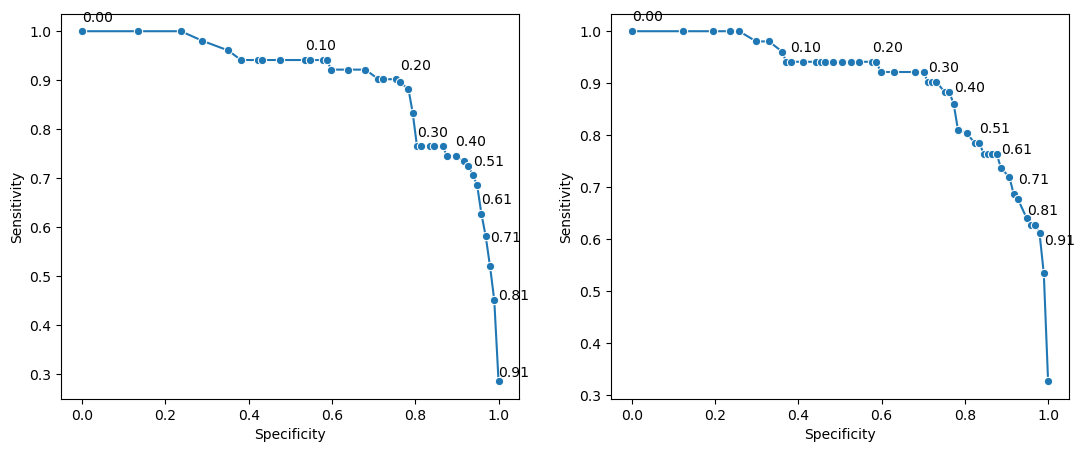

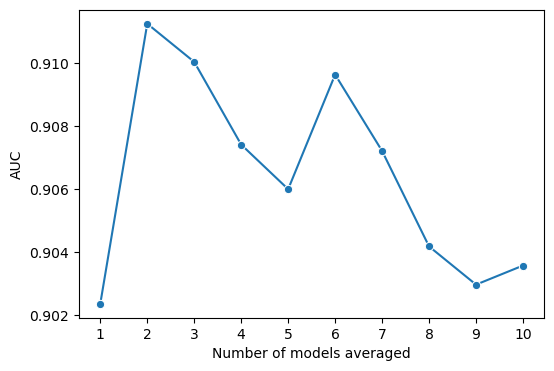

In [12]:
cutoff = 0.6623339340000001
def calc_metrics(this_df, pred_col):
    preds = this_df[pred_col]
    labels = this_df['PET_jco']

    metrics = {}
    metrics['roc_auc'] = roc_auc_score(labels, preds)
    metrics['sensitivity'] = recall_score(labels, preds > cutoff)
    metrics['specificity'] = recall_score(labels, preds > cutoff, pos_label=0)

    return metrics
def sensitivity_vs_specificity_plot(this_df, pred_col, ax=None):
    preds = this_df[pred_col]
    labels = this_df['PET_jco']

    sens_list = []
    spec_list = []
    text_list = []
    text_x_list = []
    text_y_list = []
    color_list = []
    for i, cutoff in enumerate(np.linspace(0, 1, 100)):
        sens = recall_score(labels, preds > cutoff)
        spec = recall_score(labels, preds > cutoff, pos_label=0)
        sens_list.append(sens)
        spec_list.append(spec)
        if i % 10 == 0:
            text_list.append(f'{cutoff:.2f}')
            text_x_list.append(spec)
            text_y_list.append(sens + .02)



    # plot 1-spec (x-axis) vs sensitivity (y-axis)
    # use seaborn with markers

    sns.lineplot(x=np.array(spec_list), y=sens_list, marker='o', errorbar=None, ax=ax)
    # put text by some points
    for x, y, text in zip(text_x_list, text_y_list, text_list):
        ax.text(x, y, text)
    ax.set_xlabel('Specificity')
    ax.set_ylabel('Sensitivity')

def auc_vs_num_models_plot(df, mean_aucs):
    rank = np.argsort(mean_aucs)[::-1]

    aucs_by_num_models = []
    for n_models in range(1, 11):
        selected_models = rank[:n_models]
        df_restricted = df[df['model_number'].isin(selected_models)].groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
        metrics = calc_metrics(df_restricted, 'probs_mean')
        aucs_by_num_models.append(metrics['roc_auc'])
    
    plt.figure(figsize=(6,4))
    sns.lineplot(x=np.arange(1, 11), y=aucs_by_num_models, marker='o', errorbar=None)
    plt.xlabel('Number of models averaged')
    plt.ylabel('AUC')
    plt.xticks(np.arange(1, 11))

def process_df(df):
    avged_df = df.groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
    maxed_df = df.groupby('filepath').agg({'probs_max': 'mean', 'PET_jco': 'first'}).reset_index()
    
    mean_aucs = []
    for model_num in range(10):
        this_df = df[df['model_number'] == model_num]
        print(f"Model {model_num} mean AUC: {calc_metrics(this_df, 'probs_mean')['roc_auc']:.2f}")
        print(f"Model {model_num} max AUC: {calc_metrics(this_df, 'probs_max')['roc_auc']:.2f}")
        mean_aucs.append(calc_metrics(this_df, 'probs_mean')['roc_auc'])
    
    # get indices of the greatest 5 mean AUCS
    top5_indices = np.argsort(mean_aucs)[-10:]
    #print(f'Top 5 models by mean AUC: {top5_indices}')

    avged_df_restricted = df[df['model_number'].isin(top5_indices)].groupby('filepath').agg({'probs_mean': 'mean', 'PET_jco': 'first'}).reset_index()
    #avged_df_restricted = avged_df

    metrics = calc_metrics(avged_df_restricted, 'probs_mean')
    print(f'mean: {metrics}')

    fig, ax = plt.subplots(1,2, figsize = (13,5))
    sensitivity_vs_specificity_plot(avged_df, 'probs_mean', ax=ax[0])
    sensitivity_vs_specificity_plot(maxed_df, 'probs_max', ax=ax[1])

    auc_vs_num_models_plot(df, mean_aucs)

    print('Max AUC')
    print(f"max: {calc_metrics(maxed_df, 'probs_max')}")

process_df(df_single_mipview)


Model 0 mean AUC: 0.90
Model 0 max AUC: 0.90
Model 1 mean AUC: 0.88
Model 1 max AUC: 0.88
Model 2 mean AUC: 0.88
Model 2 max AUC: 0.88
Model 3 mean AUC: 0.89
Model 3 max AUC: 0.89
Model 4 mean AUC: 0.89
Model 4 max AUC: 0.89
Model 5 mean AUC: 0.87
Model 5 max AUC: 0.87
Model 6 mean AUC: 0.89
Model 6 max AUC: 0.89
Model 7 mean AUC: 0.90
Model 7 max AUC: 0.90
Model 8 mean AUC: 0.88
Model 8 max AUC: 0.88
Model 9 mean AUC: 0.89
Model 9 max AUC: 0.89
mean: {'roc_auc': 0.9155043460683242, 'sensitivity': 0.6078431372549019, 'specificity': 0.9587628865979382}
Max AUC
max: {'roc_auc': 0.9155043460683242, 'sensitivity': 0.6078431372549019, 'specificity': 0.9587628865979382}


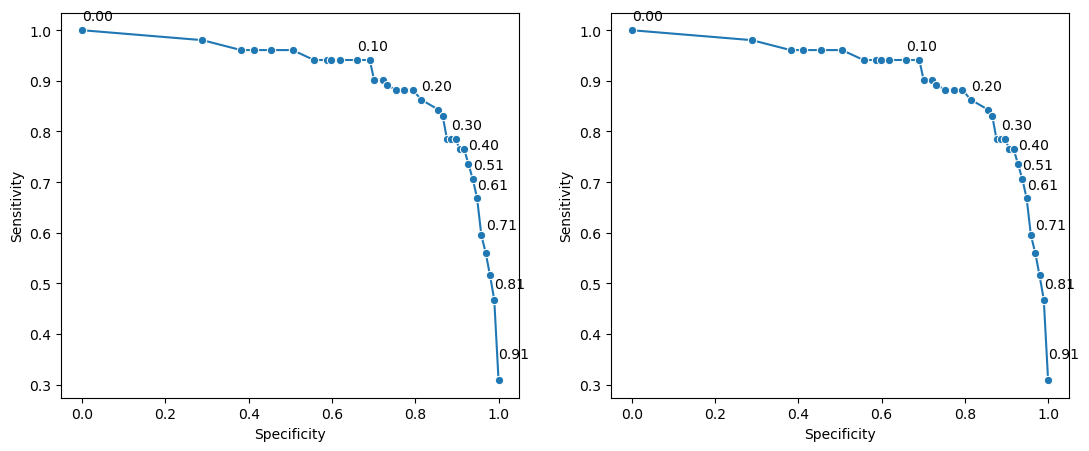

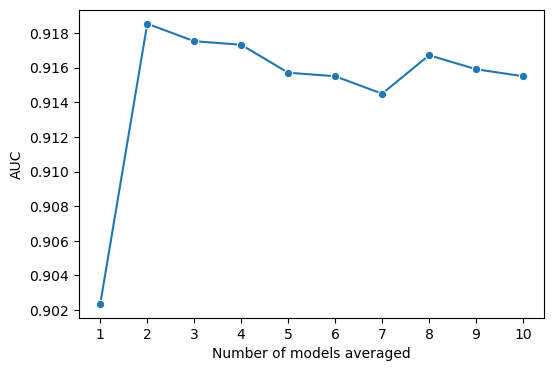

In [13]:
process_df(df_dual_mipview)

In [ ]:
# does single mipview have statistically significant difference in AUC compared to dual mipview?
def get_model_auc_list(this_df, prob_col):
    aucs = []
    for model_num in range(10):
        auc = calc_metrics(this_df[this_df['model_number'] == model_num], prob_col)['roc_auc']
        aucs.append(auc)
    return aucs

single_mean_aucs = get_model_auc_list(df_single_mipview, 'probs_mean')
dual_mean_aucs = get_model_auc_list(df_dual_mipview, 'probs_mean')

stat, p_value = ttest_rel(single_mean_aucs, dual_mean_aucs)
print(f"Paired t-test: stat={stat:.3f}, p-value={p_value:.3f}")

# again for max probabilities
single_max_aucs = get_model_auc_list(df_single_mipview, 'probs_max')
dual_max_aucs = get_model_auc_list(df_dual_mipview, 'probs_max')

# again for max probabilities

single_aucs = []
dual_aucs = []
for model_num in range(10):
    single_auc = calc_metrics(df_single_mipview[df_single_mipview['model_number'] == model_num], 'probs_max')['roc_auc']
    dual_auc = calc_metrics(df_dual_mipview[df_dual_mipview['model_number'] == model_num], 'probs_max')['roc_auc']
    single_aucs.append(single_auc)
    dual_aucs.append(dual_auc)

stat, p_value = ttest_rel(single_aucs, dual_aucs)
print(f"Paired t-test (max probs): stat={stat:.3f}, p-value={p_value:.3f}")

Paired t-test: stat=-2.403, p-value=0.040
Paired t-test (max probs): stat=-2.642, p-value=0.027


<Axes: xlabel='type', ylabel='auc'>

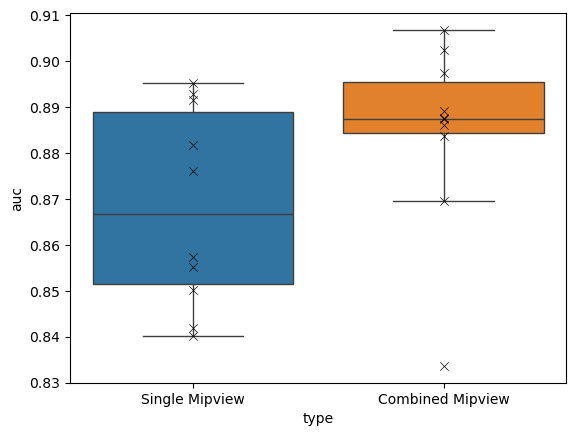

In [ ]:
# sns boxplot single_aucs and dual_aucs as groups
dicto = {'Single Mipview': single_aucs, 'Combined Mipview': dual_aucs, 'model_number': range(10)}
dfo = pd.DataFrame(dicto)
# move single_aucs and dual_aucs into a long format for seaborn
dfo_long = pd.melt(dfo, id_vars=['model_number'], value_vars=['Single Mipview', 'Combined Mipview'], var_name='type', value_name='auc')

# hide outliers
# also add markers
sns.boxplot(dfo_long, x='type', y='auc', hue='type', showfliers=False)

# markers should overly the boxplot
sns.scatterplot(dfo_long, x='type', y='auc', marker='x', color='black',zorder=5)

# add stat test using statannot


